# Часть 1. Проверка гипотезы в Python и составление аналитической записки

## Цели и задачи проекта

Цель: Статистически проверить гипотезу о том, что пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы.

Задачи:

* Проверить качество данных.

* Сравнить размеры и статистики групп.

* Проверить гипотезу.

* Интерпретировать результаты.

## Описание данных

Таблица с пользователями только из Москвы и Санкт-Петербурга находится по пути: /datasets/yandex_knigi_data.csv

* city — город пользователя;
* puid — идентификатор пользователя;
* hours — общее количество часов активности.

## Содержимое проекта

* Загрузка данных и знакомство с ними. Проверка данных на дубликаты и пропуски
* Сравнение данных между двумя группами и их распределения
* Проверка гипотезы. Проведение статистических тестов 
* Вывод.

## 1. Загрузка данных и знакомство с ними

Загрузите данные пользователей из Москвы и Санкт-Петербурга c их активностью (суммой часов чтения и прослушивания) из файла `/datasets/yandex_knigi_data.csv`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import ttest_ind

In [2]:
df_books = pd.read_csv('/datasets/yandex_knigi_data.csv')

Изучим данные и инофрмацию о них

In [3]:
df_books.head()

,Unnamed: 0,city,puid,hours
0,0,Москва,9668,26.167776
1,1,Москва,16598,82.111217
2,2,Москва,80401,4.656906
3,3,Москва,140205,1.840556
4,4,Москва,248755,151.326434


In [4]:
df_books.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8784 entries, 0 to 8783
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  8784 non-null   int64  
 1   city        8784 non-null   object 
 2   puid        8784 non-null   int64  
 3   hours       8784 non-null   float64
dtypes: float64(1), int64(2), object(1)
memory usage: 274.6+ KB


In [5]:
# Удаляем ненужный столбец
df_books.drop('Unnamed: 0', axis=1, inplace=True)

In [6]:
# Проверим данные на дубликаты
df_books.duplicated().sum()

0

In [7]:
# Проверим встречается один и тот же id 
df_books.duplicated(subset='puid').sum()

244

Обнаружено 244 неявных дубликата. Можем их удалить, чтобы оставить только уникальные id пользователей и выборка групп была корректной

In [8]:
df_books.drop_duplicates(subset=['puid'], keep=False, inplace=True)
df_books.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8296 entries, 0 to 8783
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   city    8296 non-null   object 
 1   puid    8296 non-null   int64  
 2   hours   8296 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 259.2+ KB


В результате предобработки данных в датафрейме осталось 8296 уникальных записей.

## 2. Проверка гипотезы в Python

Гипотеза звучит так: пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы. Попробуйте статистически это доказать, используя одностороннюю проверку гипотезы с двумя выборками:

- Нулевая гипотеза H₀: Средняя активность пользователей в часах в двух группах (Москва и Санкт-Петербург) не различается.

- Альтернативная гипотеза H₁: Средняя активность пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

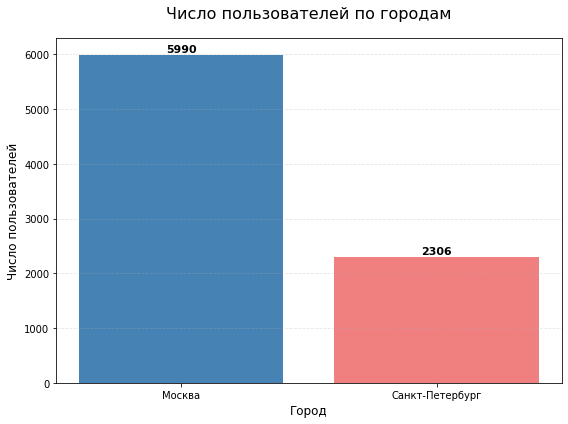

In [9]:
# Проверим распределение пользователей между группами
group_info = df_books.groupby('city')['puid'].nunique().reset_index().rename(columns={'puid': 'users'})

# Строим график
plt.figure(figsize=(8, 6))
plt.bar(group_info['city'], group_info['users'], color=['steelblue', 'lightcoral'])

plt.title('Число пользователей по городам', fontsize=16, pad=20)
plt.xlabel('Город', fontsize=12)
plt.ylabel('Число пользователей', fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)


for i, v in enumerate(group_info['users']):
    plt.text(i, v + 10, str(v), ha='center', va='bottom', fontsize=11, fontweight='bold')


plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

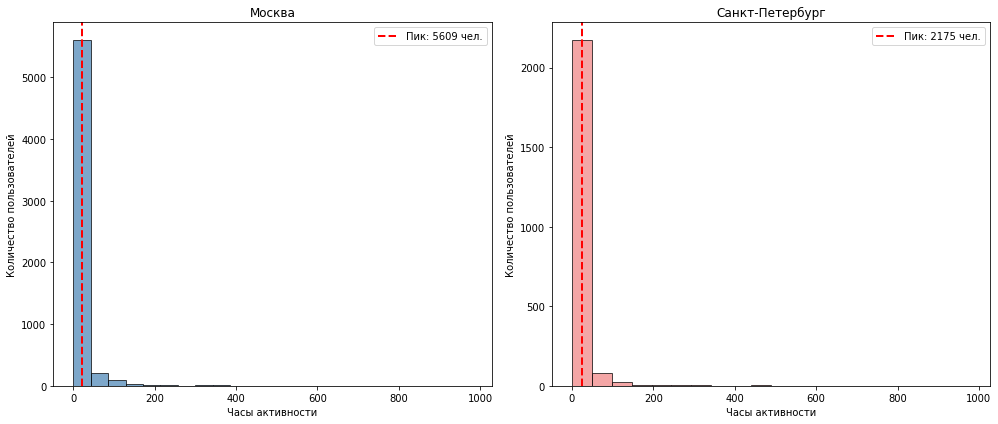

In [10]:
moscow = df_books[df_books['city'] == 'Москва']['hours']
spb = df_books[df_books['city'] == 'Санкт-Петербург']['hours']

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True)

# График для Москвы
n_mos, bins_mos, patches_mos = axes[0].hist(moscow, bins=20, alpha=0.7, color='steelblue', edgecolor='black')
axes[0].set_title('Москва')
axes[0].set_xlabel('Часы активности')
axes[0].set_ylabel('Количество пользователей')

max_idx_mos = np.argmax(n_mos)
max_val_mos = int(n_mos[max_idx_mos])
max_bin_mos = (bins_mos[max_idx_mos] + bins_mos[max_idx_mos+1]) / 2 

axes[0].axvline(max_bin_mos, color='red', linewidth=2, linestyle='--', label=f'Пик: {max_val_mos} чел.')
axes[0].legend(loc='upper right')


# График для СПб
n_spb, bins_spb, patches_spb = axes[1].hist(spb, bins=20, alpha=0.7, color='lightcoral', edgecolor='black')
axes[1].set_title('Санкт-Петербург')
axes[1].set_xlabel('Часы активности')
axes[1].set_ylabel('Количество пользователей')

max_idx_spb = np.argmax(n_spb)
max_val_spb = int(n_spb[max_idx_spb])
max_bin_spb = (bins_spb[max_idx_spb] + bins_spb[max_idx_spb+1]) / 2

axes[1].axvline(max_bin_spb, color='red', linewidth=2, linestyle='--', label=f'Пик: {max_val_spb} чел.')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show() 

In [11]:
# Проанализируем различия между группами более детально
df_books.groupby('city')['hours'].describe()

,count,mean,std,min,25%,50%,75%,max
city,,,,,,,,
Москва,5990.0,10.848192,36.925622,0.000022,0.057042,0.888232,5.933439,857.209373
Санкт-Петербург,2306.0,11.264433,39.831755,0.000025,0.060173,0.875355,6.138424,978.764775


Выводы: 
* Выборки в группах сильно различаются: 5990 в Мск против 2306 в СПб
* Различие средних значений 4% в сторону СПб
* У обоих групп медиана меньше 1 часа
Так что для проверки гипотезы используем t-тест Уэлча, т.к. мы имеем разные размеры групп с несимметричным распределением и большим стандартным отклонением

Проверяем гипотезу

In [12]:
alpha = 0.05

stat_welch_ttest, p_value = ttest_ind(
    moscow, 
    spb, 
    equal_var=False,
    alternative='less'
)
if p_value > alpha:
    print(f'p-value = {round(p_value, 2)}')
    print('Подтверждается нулевая гипотеза! Среднее время активности пользователей в Санкт-Петербурге не больше, чем в Москве.')
else:
    print(f'p-value = {round(p_value, 2)}')
    print('Нулевая гипотеза отвергается! Среднее время активности пользователей в Санкт-Петербурге больше, и это различие статистически значимо.')

p-value = 0.33
Подтверждается нулевая гипотеза! Среднее время активности пользователей в Санкт-Петербурге не больше, чем в Москве.


## 3. Аналитическая записка
По результатам анализа данных подготовьте аналитическую записку, в которой опишете:

- Для проверки гипотезы был выбран односторонний t-тест Уэлча, так как: дисперсии и размер групп различаются

- Распределенеие средних часов просмотра и выборочные средние между группами равны. Различия не являются статистически значимыми. P-value = 0.33

- По результатам двух тестов, P-value оказался больше чем уровень статистической значимости теста, поэтому подтверждается нулевая гипотеза о равенстве среднего время активности между Москвой и Санкт-Петербургом.

Возможные причины полученных результатов:

Выбраны два мегаполиса со схожим ритмом жизни и паттерном поведения жителей, отчего и различия в статистике между этими двумя группами небольшие.
Хотя средние значения в Санкт-Петербурге немного выше чем в Москве, эти значения могут быть достигнуты небольшой группой активных пользователей

----

# Часть 2. Анализ результатов A/B-тестирования

Теперь вам нужно проанализировать другие данные. Представьте, что к вам обратились представители интернет-магазина BitMotion Kit, в котором продаются геймифицированные товары для тех, кто ведёт здоровый образ жизни. У него есть своя целевая аудитория, даже появились хиты продаж: эспандер со счётчиком и напоминанием, так и подстольный велотренажёр с Bluetooth.

В будущем компания хочет расширить ассортимент товаров. Но перед этим нужно решить одну проблему. Интерфейс онлайн-магазина слишком сложен для пользователей — об этом говорят отзывы.

Чтобы привлечь новых клиентов и увеличить число продаж, владельцы магазина разработали новую версию сайта и протестировали его на части пользователей. По задумке, это решение доказуемо повысит количество пользователей, которые совершат покупку.

Ваша задача — провести оценку результатов A/B-теста. В вашем распоряжении:

* данные о действиях пользователей и распределении их на группы,

* техническое задание.

Оцените корректность проведения теста и проанализируйте его результаты.

## 1. Опишите цели исследования.



Гипотеза заключается в следующем: упрощение интерфейса приведёт к тому, что в течение семи дней после регистрации в системе конверсия зарегистрированных пользователей в покупателей увеличится как минимум на три процентных пункта.

## 2. Загрузите данные, оцените их целостность.


In [13]:
import seaborn as sns
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.proportion import proportions_ztest

In [14]:
participants = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_participants.csv')
events = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_events.zip',
                     parse_dates=['event_dt'], low_memory=False)

In [15]:
participants.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14525 entries, 0 to 14524
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  14525 non-null  object
 1   group    14525 non-null  object
 2   ab_test  14525 non-null  object
 3   device   14525 non-null  object
dtypes: object(4)
memory usage: 454.0+ KB


In [16]:
participants.head()

,user_id,group,ab_test,device
0,0002CE61FF2C4011,B,interface_eu_test,Mac
1,001064FEAAB631A1,B,recommender_system_test,Android
2,001064FEAAB631A1,A,interface_eu_test,Android
3,0010A1C096941592,A,recommender_system_test,Android
4,001E72F50D1C48FA,A,interface_eu_test,Mac


Датафрейм participants не содержит пропусков, проверим датафрейм events

In [17]:
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 787286 entries, 0 to 787285
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   user_id     787286 non-null  object        
 1   event_dt    787286 non-null  datetime64[ns]
 2   event_name  787286 non-null  object        
 3   details     249022 non-null  object        
dtypes: datetime64[ns](1), object(3)
memory usage: 24.0+ MB


In [18]:
events.head()

,user_id,event_dt,event_name,details
0,GLOBAL,2020-12-01 00:00:00,End of Black Friday Ads Campaign,ZONE_CODE15
1,CCBE9E7E99F94A08,2020-12-01 00:00:11,registration,0.0
2,GLOBAL,2020-12-01 00:00:25,product_page,NaN
3,CCBE9E7E99F94A08,2020-12-01 00:00:33,login,NaN
4,CCBE9E7E99F94A08,2020-12-01 00:00:52,product_page,NaN


In [19]:
# промерим встречается ли значения global в тестировании
participants[participants['user_id'] == "GLOBAL"]

,user_id,group,ab_test,device


- Пропуски содержатся только в столбце details, однако для анализа нам не понадобится это поле, поэтому оставляем как есть
- Значения global в столбце user_id не будут встречаться в выборке, значит никак не повлияют на тест

## 3. По таблице `ab_test_participants` оцените корректность проведения теста:

   3\.1 Выделите пользователей, участвующих в тесте, и проверьте:

   - соответствие требованиям технического задания,

   - равномерность распределения пользователей по группам теста,

   - отсутствие пересечений с конкурирующим тестом (нет пользователей, участвующих одновременно в двух тестовых группах).

In [20]:
# Изучим пользователей, учавствующих в тесте interface_eu_test
interface_eu_test = participants[participants['ab_test'] == 'interface_eu_test']
interface_eu_test.shape[0] 


interface_eu_test = participants[participants['ab_test'] == 'interface_eu_test'].copy()


# Кто участвует в нескольких тестах (конфликт экспериментов)
# Смотрим на весь исходный датасет 'participants'
users_multi_tests = (
    participants
    .groupby('user_id')['ab_test']
    .nunique()
    .loc[lambda x: x > 1]  # Фильтруем прямо в цепочке: оставляем только тех, у кого > 1 тест
    .index
)

# Кто попал в обе группы внутри нашего теста
users_multi_groups = (
    interface_eu_test
    .groupby('user_id')['group']
    .nunique()
    .loc[lambda x: x > 1]
    .index
)

bad_users = set(users_multi_tests) | set(users_multi_groups)

print(f"Всего нужно исключить пользователей: {len(bad_users)}")

# Оставляем только тех, кого НЕТ в списке bad_users
clean_df = interface_eu_test[~interface_eu_test['user_id'].isin(bad_users)].copy()

print(f"После очистки осталось: {len(clean_df)} записей")


Всего нужно исключить пользователей: 887
После очистки осталось: 9963 записей


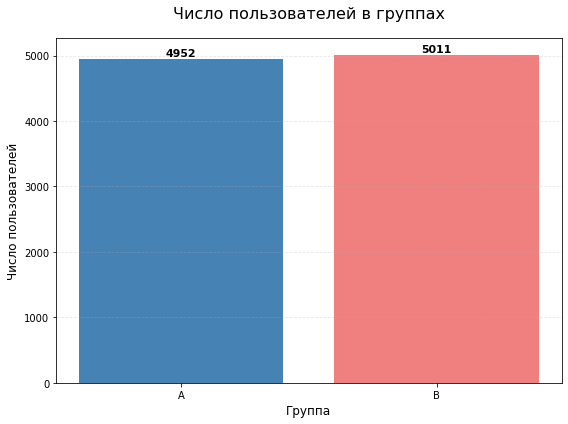

In [21]:
group_info = clean_df.groupby('group')['user_id'].nunique().reset_index().rename(columns={'user_id': 'users'})

# Строим график
plt.figure(figsize=(8, 6))
plt.bar(group_info['group'], group_info['users'], color=['steelblue', 'lightcoral'])

plt.title('Число пользователей в группах', fontsize=16, pad=20)
plt.xlabel('Группа', fontsize=12)
plt.ylabel('Число пользователей', fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)


for i, v in enumerate(group_info['users']):
    plt.text(i, v + 10, str(v), ha='center', va='bottom', fontsize=11, fontweight='bold')


plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

Разница составляет меньше 2%. 
Теперь проверим распределение пользователей по типам устройств

In [22]:
group_A = clean_df[clean_df['group'] == 'A']
group_B = clean_df[clean_df['group'] == 'B']

group_A_device = group_A.groupby('device')['user_id'].nunique().reset_index().rename(columns={'user_id': 'users'})
group_B_device = group_B.groupby('device')['user_id'].nunique().reset_index().rename(columns={'user_id': 'users'})
group_A_device['share %'] = round(group_A_device['users']/group_A_device['users'].sum() *100,2)
group_B_device['share %'] = round(group_B_device['users']/group_B_device['users'].sum() *100,2)

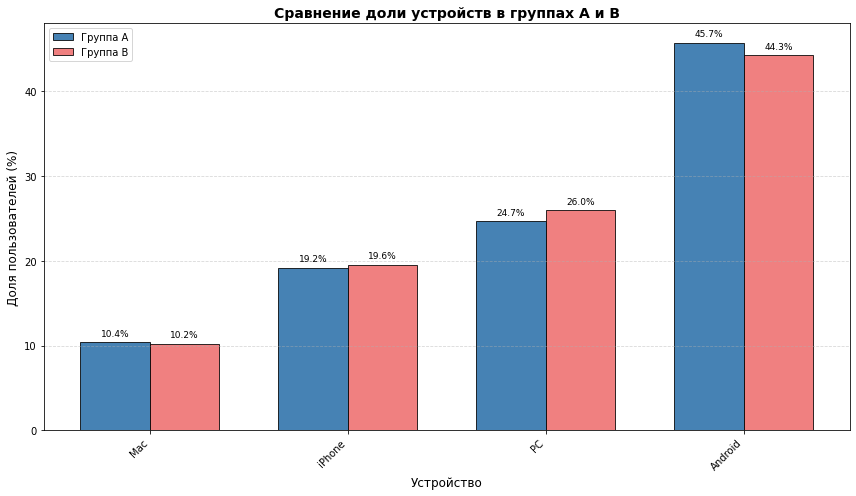

In [23]:
plot_data = pd.concat([
    group_A_device.assign(group='A'),
    group_B_device.assign(group='B')
], ignore_index=True)


order = group_A_device.sort_values('share %')['device']
plot_data['device'] = pd.Categorical(plot_data['device'], categories=order, ordered=True)
plot_data = plot_data.sort_values(['device', 'group'])

# Строим график
devices = plot_data['device'].unique()
groups = ['A', 'B']

n_devices = len(devices)
n_groups = len(groups)
bar_width = 0.35  
index = np.arange(n_devices) 

fig, ax = plt.subplots(figsize=(12, 7))

colors = {'A': 'steelblue', 'B': 'lightcoral'}

for i, group in enumerate(groups):
    data_group = plot_data[plot_data['group'] == group]
    
    positions = index + i * bar_width
    
    values = data_group['share %'].values
    
    bars = ax.bar(positions, values, bar_width, label=f'Группа {group}', 
                  color=colors[group], edgecolor='black', linewidth=0.8)
    
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, height + 0.5, 
                f'{height:.1f}%', ha='center', va='bottom', fontsize=9, color='black')


ax.set_xticks(index + bar_width / 2)
ax.set_xticklabels(devices, rotation=45, ha='right')

ax.set_xlabel('Устройство', fontsize=12)
ax.set_ylabel('Доля пользователей (%)', fontsize=12)
ax.set_title('Сравнение доли устройств в группах A и B', fontsize=14, fontweight='bold')

ax.legend(loc='upper left')

ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show() 

Выводы:
- В тестировании учавствуют 10850 записей
- Количественная разница между группами нормальная и составляет меньше 2 процентов
- Распределение пользователей по устройствам примерно одинаковое

3\.2 Проанализируйте данные о пользовательской активности по таблице `ab_test_events`:

- оставьте только события, связанные с участвующими в изучаемом тесте пользователями;

In [24]:
test_events = events.merge(clean_df, on='user_id')
test_events.shape[0]

73815

- определите горизонт анализа: рассчитайте время (лайфтайм) совершения события пользователем после регистрации и оставьте только те события, которые были выполнены в течение первых семи дней с момента регистрации;

In [25]:
reg_data = (
    test_events[test_events['event_name'] == 'registration']
    [['user_id', 'event_dt']]
    .assign(lifetime=lambda x: x['event_dt'] + pd.Timedelta(days=7))
)

actual_df = (
    test_events
    .merge(reg_data[['user_id', 'lifetime']], on='user_id', how='left')
    .query('event_dt <= lifetime')
)

print(f"Количество событий в первые 7 дней: {actual_df.shape[0]}") 

Количество событий в первые 7 дней: 63805


Оцените достаточность выборки для получения статистически значимых результатов A/B-теста. Заданные параметры:

- базовый показатель конверсии — 30%,

- мощность теста — 80%,

- достоверность теста — 95%.

In [26]:
baseline = 0.30
alpha = 0.05
power = 0.80
mde = 0.03

effect = proportion_effectsize(baseline, baseline + mde)

analysis = NormalIndPower()

sample_size = analysis.solve_power(
    effect_size=effect,
    power=power,
    alpha=alpha,
    ratio=1
)

sample_size

3761.596974012117

- рассчитайте для каждой группы количество посетителей, сделавших покупку, и общее количество посетителей.

In [27]:
# считаем общее количество уникальных пользователей в каждой группе
users_per_group = actual_df.groupby('group')['user_id'].nunique()

# считаем количество уникальных покупателейв каждой группе
buyers_per_group = (
    actual_df[actual_df['event_name'] == 'purchase']
    .groupby('group')['user_id']
    .nunique()
)
# считаем конверсию
conversion_df = pd.DataFrame({
    'total_users': users_per_group,
    'buyers': buyers_per_group
})

# заполняем NaN нулями, если в какой-то группе не было покупок
conversion_df = conversion_df.fillna(0)

conversion_df['conversion_rate'] = conversion_df['buyers'] / conversion_df['total_users']

print(conversion_df)

# считаем разницу
if 'A' in conversion_df.index and 'B' in conversion_df.index:
    diff_ab = conversion_df.loc['B', 'conversion_rate'] - conversion_df.loc['A', 'conversion_rate']
    print(f"\nКонверсия группы A: {conversion_df.loc['A', 'conversion_rate']:.4f}")
    print(f"Конверсия группы B: {conversion_df.loc['B', 'conversion_rate']:.4f}")
    print(f"Разница: {diff_ab:.4f}")
else:
    print("\nОшибка: В данных нет обеих групп A и B.")

       total_users  buyers  conversion_rate
group                                      
A             4952    1377         0.278069
B             5011    1480         0.295350

Конверсия группы A: 0.2781
Конверсия группы B: 0.2954
Разница: 0.0173


- сделайте предварительный общий вывод об изменении пользовательской активности в тестовой группе по сравнению с контрольной.

Выводы: 
- Необходимый размер групп для теста 3761 и соблюдается в обеих группах
- Разница конверсии между группами составила 1.7%, что показывает прирост событий в пользу тестовой группы, но не достигает ожидаемых 3%

## 4. Проведите оценку результатов A/B-тестирования:

Еще раз вспомним нашу гипотезу: упрощение интерфейса приведёт к тому, что в течение семи дней после регистрации в системе конверсия зарегистрированных пользователей в покупателей увеличится как минимум на три процентных пункта.  

Значит:  
- Нулевая гипотеза 𝐻0: Конверсия в покупку для группы B осталась без изменений относительно группы А

- Альтернативная гипотеза 𝐻1: Конверсия группы В увеличилось на 3%


- Проверьте изменение конверсии подходящим статистическим тестом, учитывая все этапы проверки гипотез.

In [28]:
# Извлекаем данные для группы A
n_a = conversion_df.loc['A', 'total_users']
x_a = conversion_df.loc['A', 'buyers']

# Извлекаем данные для группы B
n_b = conversion_df.loc['B', 'total_users']
x_b = conversion_df.loc['B', 'buyers']

# Z-тест
alpha = 0.05

stat_ztest, p_value_ztest = proportions_ztest(
    [x_a, x_b],
    [n_a, n_b],
    alternative='smaller'
)

if p_value_ztest > alpha:
    print(f'p-value={p_value_ztest} > {alpha}')
    print('Нулевая гипотеза находит подтверждение!')
else:
    print(f'p-value={p_value_ztest} < {alpha}')
    print('Нулевая гипотеза не находит подтверждения!')

p-value=0.028262547212292124 < 0.05
Нулевая гипотеза не находит подтверждения!


Выводы:  
- p-value составил 0.02, что отвергает нулевую гипотезу, т.к. тендения показала рост. 
- Однако стоит заметить, что значение конверсии хоть и увеличилось, но не достигло ожидаемых 3%.  

Рекомендации:  
- Т.к. тестовая группа показала статистически значимый рост, хоть и меньше ожидаемого, логичнее всего уже интегрировать изменения в приложение(ресурсы все равно уже потрачены, а рост принесет дополнительную прибыль)
- Если заданный порог в 3% критически необходим, можно попробовать провести более длительный тест, чтобы зафиксировать рост на большей дистанции или с большим количеством пользователей